# Gradient Descent Animation — Updating Only `b`

This notebook keeps the slope `m` fixed and updates only the intercept `b`.
Run the cells from top to bottom.

In [1]:
from sklearn.datasets import make_regression

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

## 1. Generate and visualize the dataset

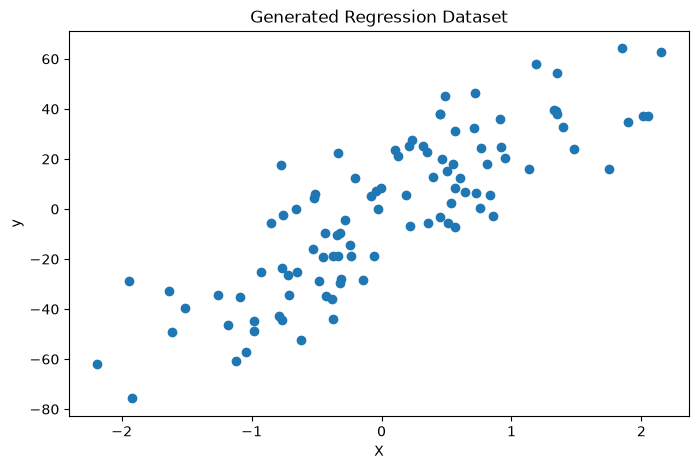

X shape: (100, 1)
y shape: (100,)


In [2]:
X, y = make_regression(
    n_samples=100,
    n_features=1,
    n_informative=1,
    n_targets=1,
    noise=20,
    random_state=13
)

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated Regression Dataset")
plt.show()

print("X shape:", X.shape)
print("y shape:", y.shape)

## 2. Find a reference Linear Regression result

This is only for comparison. The animation below uses the manually initialized `m` and updates only `b`.

In [3]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X, y)

print("Sklearn slope:", reg.coef_[0])
print("Sklearn intercept:", reg.intercept_)

Sklearn slope: 27.82809103252014
Sklearn intercept: -2.29474455867698


## 3. Gradient Descent — update only `b`

In [4]:
# Keep m fixed; update only b
m = 27.82
b = -150.0

lr = 0.001
epochs = 30

all_b = []
all_cost = []
num_epochs = []

# Use 1D arrays/scalars to avoid shape (1,) values
x_values = X[:, 0]
y_values = y.ravel()

for epoch in range(epochs):
    slope = 0.0
    cost = 0.0

    for j in range(len(x_values)):
        error = y_values[j] - (m * x_values[j] + b)

        # Gradient with respect to b
        slope += -2 * error

        # Sum of squared errors
        cost += error ** 2

    # Update b after calculating the gradient for the whole dataset
    b = b - lr * slope

    # Save values for animations
    all_b.append(b)
    all_cost.append(cost)
    num_epochs.append(epoch + 1)

all_b = np.array(all_b)
all_cost = np.array(all_cost)
num_epochs = np.array(num_epochs)

print("Final m (fixed):", m)
print("Final b:", b)
print("Epochs:", epochs)
print("Final recorded cost:", all_cost[-1])

Final m (fixed): 27.82
Final b: -2.4771228173203603
Epochs: 30
Final recorded cost: 28347.50541622337


## 4. Animate the regression line

Because this notebook updates only `b`, the slope `m` remains fixed while the line moves up/down.

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(x_values, y_values, label="Data")
x_line = np.linspace(x_values.min(), x_values.max(), 100)

line, = ax.plot(
    x_line,
    m * x_line + all_b[0],
    "r-",
    linewidth=2,
    label="Regression line"
)

ax.set_xlim(x_values.min() - 0.5, x_values.max() + 0.5)
all_line_y = m * x_line[None, :] + all_b[:, None]
y_min = min(y_values.min(), all_line_y.min()) - 20
y_max = max(y_values.max(), all_line_y.max()) + 20
ax.set_ylim(y_min, y_max)
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.legend()

def update_regression(i):
    line.set_ydata(m * x_line + all_b[i])
    ax.set_title(f"Regression Line — Epoch {num_epochs[i]}")
    return line,

reg_anim = animation.FuncAnimation(
    fig,
    update_regression,
    frames=len(num_epochs),
    interval=300,
    repeat=False,
    blit=True
)

reg_anim.save("regression_line_animation.gif",
              writer=animation.PillowWriter(fps=3),
              dpi=70)

display(HTML(reg_anim.to_jshtml()))
plt.close(fig)

## 5. Animate Cost vs Epoch

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

line, = ax.plot([], [], linewidth=2)
ax.set_xlim(1, epochs)
ax.set_ylim(0, float(all_cost.max()) * 1.05)
ax.set_title("Cost Function — Gradient Descent")
ax.set_xlabel("Epoch")
ax.set_ylabel("Sum of Squared Errors")
ax.grid(True)

xdata, ydata = [], []

def animate_cost(i):
    xdata.append(num_epochs[i])
    ydata.append(all_cost[i])
    line.set_data(xdata, ydata)
    ax.set_title(f"Cost Function — Epoch {num_epochs[i]}")
    return line,

cost_anim = animation.FuncAnimation(
    fig,
    animate_cost,
    frames=len(num_epochs),
    interval=300,
    repeat=False,
    blit=True
)

cost_anim.save("cost_animation.gif",
               writer=animation.PillowWriter(fps=3),
               dpi=70)

display(HTML(cost_anim.to_jshtml()))
plt.close(fig)

## 6. Animate `b` vs Epoch

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

line, = ax.plot([], [], linewidth=2)
ax.set_xlim(1, epochs)
ax.set_ylim(float(all_b.min()) - 10, float(all_b.max()) + 10)
ax.set_title("Intercept b — Gradient Descent")
ax.set_xlabel("Epoch")
ax.set_ylabel("b")
ax.grid(True)

xdata, ydata = [], []

def animate_b(i):
    xdata.append(num_epochs[i])
    ydata.append(all_b[i])
    line.set_data(xdata, ydata)
    ax.set_title(f"Intercept b — Epoch {num_epochs[i]}")
    return line,

b_anim = animation.FuncAnimation(
    fig,
    animate_b,
    frames=len(num_epochs),
    interval=300,
    repeat=False,
    blit=True
)

b_anim.save("b_animation.gif",
            writer=animation.PillowWriter(fps=3),
            dpi=70)

display(HTML(b_anim.to_jshtml()))
plt.close(fig)

## 7. Cost for different values of `b`

This static plot shows how the cost changes when `b` is varied while `m` remains fixed.

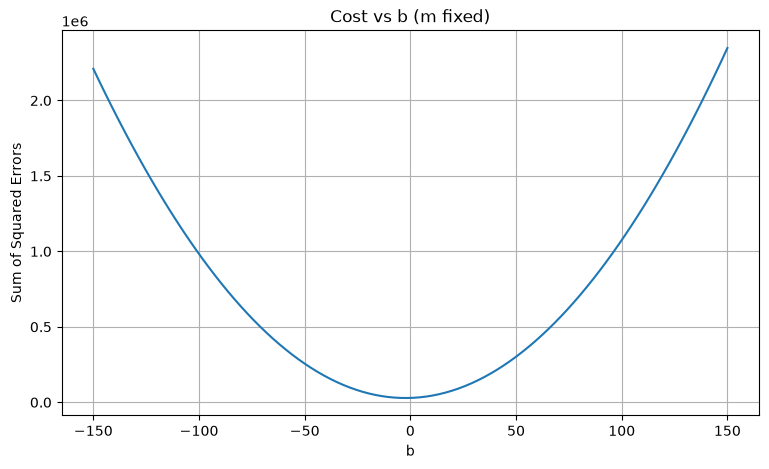

In [8]:
b_input = np.linspace(-150, 150, 100)
cost_input = []

for b_value in b_input:
    predictions = m * x_values + b_value
    this_cost = np.sum((y_values - predictions) ** 2)
    cost_input.append(this_cost)

plt.figure(figsize=(9, 5))
plt.plot(b_input, cost_input)
plt.xlabel("b")
plt.ylabel("Sum of Squared Errors")
plt.title("Cost vs b (m fixed)")
plt.grid(True)
plt.show()